In [74]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langgraph.graph import StateGraph, END
from pydantic import BaseModel
from langchain_ollama import ChatOllama

from IPython.display import display, Image
import graphviz
import os

In [56]:
Google_API_KEY = os.environ.get("GOOGLE_API_KEY")

In [57]:
LLM = ChatGoogleGenerativeAI(google_api_key=Google_API_KEY, model="gemini-3.8-flash", temperature=0)

In [58]:
class UserInput(BaseModel):
    message: str
    response: str = None

In [59]:
def agent_node(state: UserInput) -> UserInput:
    prompt = ChatPromptTemplate.from_template(
        "User asked: {message}. "
        "Rephrase this as just a city name for weather lookup."
    )

    chain = prompt | LLM
    # UserInput is a Pydantic model, so access the original request as an attribute.
    response = chain.invoke({"message": state.message}).text
    return {"message": response, "response": ""}


def weather_tool(state: UserInput) -> UserInput:
    # The agent stores the normalized city name in the model's message field.
    city = state.message.lower().strip()
    weather_data = {
        "new york": {"temperature": 22, "condition": "sunny"},
        "los angeles": {"temperature": 28, "condition": "cloudy"},
        "chicago": {"temperature": 18, "condition": "rainy"},
        "houston": {"temperature": 30, "condition": "sunny"},
        "phoenix": {"temperature": 35, "condition": "hot"},
    }
    forecast = weather_data.get(city, f"Sorry, I don't have weather information for {city}.")
    return {"message": state.message, "response": forecast}

In [60]:
graph = StateGraph(UserInput)
graph.add_node("agent", agent_node)
graph.add_node("weather", weather_tool)

graph.set_entry_point("agent")
graph.add_edge("agent", "weather")
graph.add_edge("weather", END)

app = graph.compile()

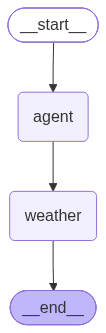

In [61]:
png_bytes = app.get_graph().draw_mermaid_png()
display(Image(png_bytes))

In [62]:
app.invoke({"message": "What's the weather like in New York?", "response": ""})

{'message': 'New York', 'response': {'temperature': 22, 'condition': 'sunny'}}

In [63]:
app.invoke({"message": "What's the weather like in New Delhi?", "response": ""})

{'message': 'New Delhi',
 'response': "Sorry, I don't have weather information for new delhi."}

In [64]:
Google_API_KEY = os.environ.get("GOOGLE_API_KEY")

In [75]:
LLM = ChatOllama(model = "qwen3:4b", system_prompt = "You are a helpful assistant.", temperature = 0)

In [84]:
class user_chat(BaseModel):
    message: str
    translate_word: str = None
    response: str = None

In [98]:
def ollama_node(state: user_chat) -> user_chat:
    prompt = ChatPromptTemplate.from_template(
        "user_chat: {message}. "
        "Identify the word in message that needs to be translated to English: "
    )
    chain = prompt | LLM
    answer = chain.invoke({"message": state.message}).content
    return {"translate_word": answer, "response": ""}

def translate_tool(state: user_chat) -> user_chat:
    # The agent stores the word to be translated in the model's message field.
    word_to_translate = state.translate_word.strip().lower()
    translation_data = {
        "hola": "hello",
        "adiós": "goodbye",
        "gracias": "thank you",
        "porfavor": "please",
        "sí": "yes",
        "no": "no",
    }
    translation = translation_data.get(word_to_translate, f"Sorry, I don't have a translation for {word_to_translate}.")
    return {"message": state.message, "response": translation}

In [99]:
agent_graph = StateGraph(user_chat)
agent_graph.add_node("ollama", ollama_node)
agent_graph.add_node("translate", translate_tool)

agent_graph.set_entry_point("ollama")
agent_graph.add_edge("ollama", "translate")
agent_graph.add_edge("translate", END)

app2 = agent_graph.compile()

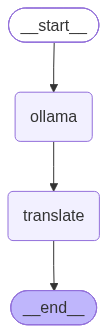

In [100]:
png_bytes = app2.get_graph().draw_mermaid_png()
display(Image(png_bytes))

In [101]:
app2.invoke({"message": "Hola, ¿cómo estás?", "response": ""})

{'message': 'Hola, ¿cómo estás?',
 'translate_word': 'Hola',
 'response': 'hello'}

In [ ]:
app2.invoke({"message": "What does this spanish word meaning por favor in english?", "response": ""})

{'message': 'What does porfavor mean?',
 'translate_word': 'The phrase **"porfavor"** is a **common misspelling of the Spanish phrase "por favor"** (which means **"please"** in English).  \n\n### Key points:\n1. **It needs translation to English** → **"please"**  \n2. **Why it\'s a typo**:  \n   - Correct Spanish: **"por favor"** (two words, with a space).  \n   - Common misspelling: **"porfavor"** (no space, missing the "r" in "favor").  \n3. **Which word needs translation?**  \n   → **The entire phrase "porfavor"** (as a single unit) needs translation to English.  \n   → *But technically, it\'s two Spanish words*:  \n     - **"por"** = "for" (preposition)  \n     - **"favor"** = "favor" (noun, meaning "please" in this context)  \n   → **In practice, this phrase is always translated as one English word: "please"**.\n\n### Answer to your question:\n- **What "porfavor" means**: **"please"** (in English).  \n- **The word/phrase that needs translation**: **"porfavor"** (the entire misspel

In [ ]:
app2.invoke({"message": "What does this spanish word meaning gracias in english?", "response": ""})

{'message': 'What does gracias mean?',
 'translate_word': 'The word in your message that needs to be translated to English is: **gracias**.\n\nHere\'s why:\n- **"gracias"** is a Spanish word meaning **"thank you"** (used in the context of "thank you for your help" or similar).\n- Your message (`What does gracias mean?`) contains **only this one Spanish word** ("gracias"). There are no other words in the message that need translation.\n- Since you\'re asking for the translation of *this specific word*, **"gracias"** is the target for translation.\n\n### Quick Translation:\n| Spanish | English |\n|---------|---------|\n| **gracias** | **thank you** |\n\n💡 **Note**: In your query, the phrase *"What does gracias mean?"* is the **question** you\'re asking (not the message to translate). The actual word you need to translate is **"gracias"** (the Spanish word itself). \n\nIf you have a longer message with multiple words (e.g., "Gracias por tu ayuda"), I’d help identify *which specific words*

{'message': 'What does por favor mean?',
 'translate_word': 'The user\'s message is: "What does por favor mean?. Identify the word in message that needs to be translated to English:"\n\nIn this message, the phrase **"por favor"** (written in Spanish) needs to be translated to English. This is the only foreign-language unit in the message that requires translation. While "por" and "favor" are technically two separate words in Spanish, the context of the query (asking about the meaning of "por favor" as a common phrase) indicates that the entire phrase is the unit that needs translation. The problem specifies "the word," but in this case, the intended unit is the Spanish phrase "por favor" (meaning "please" in English).\n\n**Answer: por favor**',
 'response': 'Sorry, I don\'t have a translation for the user\'s message is: "what does por favor mean?. identify the word in message that needs to be translated to english:"\n\nin this message, the phrase **"por favor"** (written in spanish) ne